# Step 0 - AIRR data ingestion


vAIRRify runs on AIRR-seq clonotype tables, which are ingested into a common format.
This approach supports various input table - MiXCR output, AIRR format, CellRanger output, Adaptive ImmunoSeq, etc.


Three things are required for the data ingestion step:

1. **The actual data** , provided as a directory with clonotype table files. These can be csv, tsv, etc, and one of the various supported formats. By default, we use the data/raw (`RAW_DATA_DIR`) for this, but you can point to any directory.

2. **A mapping from filename -> repertoire_id and from filename -> patient_id.** The tool needs to know which sequencing files relate to which unique biological sample (`repertoire_id`), and how they map to patients (`patient_id`). These two key identifiers can ofcourse be identical in dasets where there is one sample from each patient. The most straightforward way to specify these mappings is using a regex-like syntax, but other options (e.g. providing a csv with filename,repertoire_id,patient_id) are also possible.

3. **Metadata** can be added on a patient-level (e.g. ethnicity, sex) or repertoire-level (e.g. sequencing batch, disease status, ...), as a polars dataframe with the same patient_id or repertoire_id keys as produced by the mapping. 


This notebooks is divided into two sections:
1. Data ingestion itself
2. Quick checks to see if the ingestion was succesful

In [ ]:
from pathlib import Path
import polars as pl

In [17]:
from tcr_io.mappers import RegexMapper
from tcr_io.ingestion import DatasetIngester

## 1. Data ingestion

In [14]:
# specify the path to the input clonotype tables 
data_path = Path("../data/raw")

# this can also be a custom path: data_path = Path("/path/to/your/clonotype/files")
data_path = Path("/data/current/projects/zaslavsky_analysis/data/airr_format")

In [16]:
# specify how to extract the repertoire_id (sample name) and patient_id (patient name)

# option 1 : using Regex
repertoire_mapper = RegexMapper(r"part_table_(BFI-\d+)_.*\.tsv", group=1)
patient_mapper = RegexMapper(r"part_table_(BFI-\d+)_.*\.tsv", group=1)

In [21]:
# specify how data should be ingested

ingested_dir = Path("../data/processed")
dataset_name = "zaslavsky"

di = DatasetIngester(
    db_dir = ingested_dir,
    db_name = dataset_name,
    repertoire_mapper=repertoire_mapper,
    patient_mapper=patient_mapper,
)

In [26]:
di._test_mappers(data_path) # test if the mappers work correctly on the files in the data_path

Repertoire mapping : 
-------------------
Pattern: part_table_(BFI-\d+)_.*\.tsv
* group 1: BFI-\d+
Success rate: 1.0
Succesfully extracted:
BFI-0000234 <- part_table_BFI-0000234_TCR.tsv.gz, part_table_BFI-0000234_BCR.tsv.gz
BFI-0000254 <- part_table_BFI-0000254_TCR.tsv.gz, part_table_BFI-0000254_BCR.tsv.gz
BFI-0000255 <- part_table_BFI-0000255_TCR.tsv.gz, part_table_BFI-0000255_BCR.tsv.gz
BFI-0000256 <- part_table_BFI-0000256_TCR.tsv.gz, part_table_BFI-0000256_BCR.tsv.gz
BFI-0000258 <- part_table_BFI-0000258_TCR.tsv.gz, part_table_BFI-0000258_BCR.tsv.gz
BFI-0002850 <- part_table_BFI-0002850_TCR.tsv.gz, part_table_BFI-0002850_BCR.tsv.gz
BFI-0002851 <- part_table_BFI-0002851_TCR.tsv.gz, part_table_BFI-0002851_BCR.tsv.gz
BFI-0002852 <- part_table_BFI-0002852_TCR.tsv.gz, part_table_BFI-0002852_BCR.tsv.gz
BFI-0002854 <- part_table_BFI-0002854_TCR.tsv.gz, part_table_BFI-0002854_BCR.tsv.gz
BFI-0002855 <- part_table_BFI-0002855_TCR.tsv.gz, part_table_BFI-0002855_BCR.tsv.gz
BFI-0002856 <- part_

In [28]:
# run the ingestion process
# this might take a while, depending on the number of files, their compression, and size
# note - if the file type is not automatically recognized, you might need a specialized reader. See the documentation for more details.

ds = di.run(data_path)

Reading repertoires: 100%|██████████| 593/593 [07:53<00:00,  1.25it/s, Reader: synapse (inferred), IGH+TRB]


In [30]:
ds

Processed Dataset 'zaslavsky', dataset v8, 
        present loci ['IGH', 'TRB'],
        created_on 2026-10-23, 
        86948924 clonotypes (593 repertoires, 593 patients),
        

## 2. Adding metadata

In this step, the goal is to add all useful metadata for your samples. Metadata is either defined on a patient-level, or on a sample-level, which should map to a repertoire's patient_id and repertoire_id, respectively. The dataframes should be provided as a polars dataframe, with one row per unique identifier.

In [ ]:
# read the metadata file
metadata = pl.read_csv("/data/current/datasets/public/zaslavsky_2025/meta/metadata.tsv", separator="\t")

In [41]:
# split up in patient and repertoire-level metadata
patient_meta = metadata.select(
    pl.col("participant_label").alias("patient_id"),
    pl.col("age"),
    pl.col("sex"),
    pl.col("ancestry")
).unique()

repertoire_meta = metadata.select(
    pl.col("participant_label").alias("repertoire_id"),
    pl.col("study_name"),
    pl.col("disease"),
    pl.col("disease_subtype"),
    pl.col("malid_cross_validation_fold_id_when_in_test_set")
).unique()

In [ ]:
# store the metadata in the dataset

ds.metadata.set_patient(patient_meta)
ds.metadata.set_repertoire(repertoire_meta)

## 3. General QC of data ingestion

The dataset ingestion process comprised the following steps:

1. Extracting the correct columns from the clonotype files (specified by tcr_io.reader), and renaming them to AIRR format
2. Mapping V and J genes to IMGT notation (e.g. Adaptive format to IMGT)
3. Extracting and trimming the junction nucleotide sequence to the junction_aa length (for some datasets, junction comprises the full sequenced fragment)
4. Deduplicating rows within a repertoire, based on v_call, j_call, junction sequence. Duplicate counts for these rows are summed
5. Filtering out invalid rows, if they fail one of these steps

To check if these steps executed correctly, a filtering report is generated, which specifies how many rows were filtered out, and for which reasons.

In [43]:
from tcr_io import operations as ops

In [44]:
ds.run_operation(ops.FilteringReport())

Filtering report (_unassigned): 100%|██████████| 584/584 [00:00<00:00, 745.56it/s]


[OperationRecord(operation_name='filtering_report', version='0.6', description='Per-locus report of why sequences were excluded: quality failures on each present locus, assignment failures on the _unassigned partition.', ran_at=datetime.datetime(2026, 10, 23, 14, 33, 13, 302234), duration_s=4.818139314651489, status='success', error=None, params={'top_n': 100}, locus='IGH', outputs=[OutputRecord(name='filter_summary', template='filter_summary.parquet', format='PARQUET'), OutputRecord(name='filter_top', template='filter_top_invalid_junction_aa.parquet', format='PARQUET'), OutputRecord(name='filter_top', template='filter_top_invalid_v_call.parquet', format='PARQUET'), OutputRecord(name='filter_top', template='filter_top_non_functional_v_call.parquet', format='PARQUET'), OutputRecord(name='filter_top', template='filter_top_null_junction.parquet', format='PARQUET'), OutputRecord(name='filter_reason_totals', template='filter_reason_totals.parquet', format='PARQUET'), OutputRecord(name='filt

In [49]:
## 3.1. Locus unassigned

ds.select_locus("_unassigned").get_result(ops.FilteringReport.filter_reason_totals).read()

reason,n_failed_rows,n_distinct_values
str,i64,u32
"""incompatible_locus""",19063,31


In [54]:
ds.select_locus("_unassigned").get_result(ops.FilteringReport.filter_summary).read()

repertoire_id,incompatible_locus
str,i64
"""BFI-0000234""",65
"""BFI-0000254""",39
"""BFI-0000255""",71
"""BFI-0000256""",31
"""BFI-0000258""",110
…,…
"""BFI-0010791""",2
"""BFI-0010792""",4
"""BFI-0010794""",4


In [82]:
## 3.2. Within one locus

locus = "TRB"

In [83]:
# overview of the filtering reasons for a specific locus
ds.select_locus(locus).get_result(ops.FilteringReport.filter_reason_totals).read()

reason,n_failed_rows,n_distinct_values
str,i64,u32
"""null_junction""",194789,1
"""invalid_junction_aa""",592231,542384
"""invalid_v_call""",381,2
"""non_functional_v_call""",21027,15


In [84]:
# to get insight in the top distinct values that got filtered, have a look at the following table

reason = "invalid_v_call"

ds.select_locus(locus).get_result(ops.FilteringReport.filter_top, reason=reason).read().head()

v_call,count
str,u32
"""TRBV25/OR9-2*01""",254
"""TRBV6-2*02""",127


In [ ]:
# to get insight in the top distinct values that got filtered, have a look at the following table

reason = "non_functional_v_call" # valid IMGT notation, but pseudogene 

ds.select_locus(locus).get_result(ops.FilteringReport.filter_top, reason=reason).read().head()

v_call,count
str,u32
"""TRBV6-7*01""",9196
"""TRBV5-7*01""",7821
"""TRBV12-2*01""",1592
"""TRBV20/OR9-2*02""",1283
"""TRBV7-3*03""",451


In [110]:
# to have an overview per repertoire, you can use the following strategy:

filter_totals = ds.select_locus(locus).get_result(ops.FilteringReport.filter_summary).read()
counts = ds.select_locus(locus).repertoire_counts.with_columns(
    fraction_valid = (pl.col("n_clonotypes") - pl.col("n_filtered_clonotypes")) / pl.col("n_clonotypes")
)

filter_report = filter_totals.join(counts, on="repertoire_id", how="left").join(
    ds.full_repertoire_meta, on="repertoire_id", how="left" # add repertoire-level metadata
).join(
    ds.full_patient_meta, on="patient_id", how="left" # add patient-level metadata
).drop(pl.selectors.by_dtype(list))

In [114]:
filter_report.head()

repertoire_id,null_junction,invalid_junction_aa,invalid_v_call,non_functional_v_call,n_clonotypes,n_filtered_clonotypes,total_duplicates,fraction_valid,patient_id,study_name,disease,disease_subtype,malid_cross_validation_fold_id_when_in_test_set,n_repertoires,age,sex,ancestry
str,i64,i64,i64,i64,i64,i64,i64,f64,str,str,str,str,i64,i64,i64,str,str
"""BFI-0000234""",360,934,0,26,75797,1320,174649,0.982585,"""BFI-0000234""","""HIV""","""Healthy/Background""","""Healthy/Background - HIV Negat…",1,1,27,"""M""",null
"""BFI-0000254""",328,579,0,45,52411,952,108174,0.981836,"""BFI-0000254""","""HIV""","""HIV""","""HIV Broad Neutralizing""",0,1,48,"""F""","""African"""
"""BFI-0000255""",318,711,3,24,50897,1056,134821,0.979252,"""BFI-0000255""","""HIV""","""HIV""","""HIV Broad Neutralizing""",2,1,33,"""F""","""African"""
"""BFI-0000256""",377,736,1,16,53964,1130,151136,0.97906,"""BFI-0000256""","""HIV""","""HIV""","""HIV Broad Neutralizing""",2,1,31,"""F""","""African"""
"""BFI-0000258""",438,1407,0,76,104811,1921,236857,0.981672,"""BFI-0000258""","""HIV""","""HIV""","""HIV Non Neutralizing""",1,1,49,"""F""","""African"""


<Axes: xlabel='n_clonotypes', ylabel='fraction_valid'>

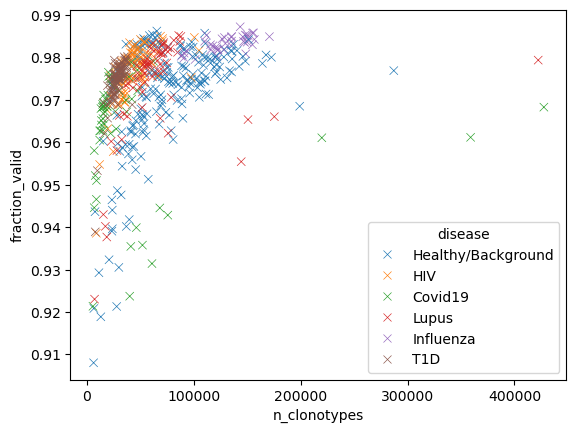

In [ ]:
sns.scatterplot(
    data = filter_report,
    x = "n_clonotypes",
    y = "fraction_valid",
    marker="x",
    hue="disease"
) # this looks good - high mapping percentages